# FlightOps ML — Feature Engineering & Model Ensembling
## Unlocking Airspace Physics, Traffic Bottlenecks, and Multi-Model Blending

> **Dataset:** 4,510,362 domestic flights across the Top 50 US Hubs in 2025.
> **Train Split:** Jan 1 – Aug 31, 2025 (3,601,394 flights)
> **Validation Split:** Sep 1 – Oct 31, 2025 (908,968 flights)
> **Prediction Horizon:** Strict cutoff at **2 hours prior to scheduled departure** ($T_{\text{obs}} \le T_{\text{dep}} - 2\text{h}$).
> **Target:** Binary departure delay indicator `dep_del15` ($\ge 15$ minutes late).

---

### Overview: Feature Engineering Results
In our previous experiment, we learned a humbling lesson:
> **Raw machine learning without domain features struggled against a simple lookup table.

To build a truly world-class prediction engine, we engineered **4 distinct domain feature families**:
1. **Airport Traffic & Runway Saturation:** Using SQL window functions to measure hourly takeoff queues.
2. **Atmospheric Physics:** Wind gust shear, dewpoint condensation spreads, and cyclonic pressure drops.
3. **Carrier Hub Dominance:** Fleet market share per origin airport.
4. **Bayes-Smoothed Target Priors:** Strict out-of-fold historical delay priors calculated *only on the train split*.

Then, we introduced **CatBoost** alongside **LightGBM** and **Logistic Regression**, and combined their predictions into an **Optimized Blended Meta-Ensemble**.

---

### The Head-to-Head Scoreboard (908,968 Validation Flights)

| Contender Model | ROC-AUC | PR-AUC (Target: High) | Brier Score (Target: Low) | Delays Caught (Recall at $\tau^*$) | Optimal Trigger ($\tau^*$) |
|---|:---:|:---:|:---:|:---:|:---:|
| **Model 3: Logistic Regression (Engineered)** | `0.6909` | `0.3402` | `0.1447` | 67.8% | $\tau = 0.25$ |
| **Model 2: CatBoost (Engineered + Weather)** | `0.6932` | `0.3424` | `0.1428` | 68.2% | $\tau = 0.23$ |
| **Model 1: LightGBM (Engineered + Weather)** | `0.6989` | `0.3504` | `0.1415` | 68.6% | $\tau = 0.20$ |
| 🏆 **Model 4: Blended Meta-Ensemble** | **`0.6996`** | **`0.3510`** | **`0.1415`** | **68.7%** | $\tau = 0.21$ |

> **Key Win:** The Blended Ensemble achieved our all-time best performance across ranking (**ROC-AUC: 0.6996**), precision-recall (**PR-AUC: 0.3510**), and probability calibration (**Brier: 0.1415**)!

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Styling for publication-grade visuals
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.sans-serif": "Arial",
    "figure.titlesize": 15,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 150,
})

# Load the official ensemble scoreboard JSON
with open("../docs/FEATURE_ENGINEERED_ENSEMBLE_SCOREBOARD.json", "r") as f:
    ensemble_data = json.load(f)

print(f"Loaded evaluation across {ensemble_data['validation_flights']:,} validation flights.")
print(f"Ensemble Learned Weights: {ensemble_data['ensemble_weights']}")

Loaded evaluation across 908,968 validation flights.
Ensemble Learned Weights: {'lightgbm': 0.897, 'catboost': 0.0, 'logistic_regression': 0.103}


---
## Chapter 1: The 4 Feature Engineering Buckets
### Teaching Machine Learning the Laws of Aviation

In real-world data science, algorithms don't know what an airplane is. They only know matrices.
To give our models real physical intuition, we engineered **4 distinct feature families**:

```mermaid
flowchart TD
subgraph F1["1. Airport Traffic Pressure"]
A["origin_hourly_flights<br/>(Runway Queue Size)"]
B["carrier_hub_daily_flights<br/>(Carrier Fleet Size)"]
C["carrier_hub_share<br/>(Gate Dominance Ratio)"]
end
subgraph F2["2. Atmospheric Physics"]
D["wind_gust_spread<br/>(Turbulence / Shear)"]
E["temp_dewpoint_spread<br/>(Fog / Low Cloud Ceiling)"]
F["pressure_anomaly<br/>(Cyclonic Front Indicator)"]
G["severe_weather_composite<br/>(Weighted Storm Index)"]
end
subgraph F3["3. Bayesian Target Priors"]
H["prior_carrier_hour_risk<br/>(Smoothed Airline Schedule Risk)"]
I["prior_origin_hour_risk<br/>(Smoothed Airport Schedule Risk)"]
J["prior_carrier_origin_risk<br/>(Airline-Airport Synergy)"]
end
```

#### 1. Airport Traffic Pressure (SQL Window Functions)
- **`origin_hourly_flights`:** How many other planes are scheduled to take off from the same runway complex in the same hour? If an airport rated for 40 takeoffs schedules 55, runway taxi queues are guaranteed.
- **`carrier_hub_share`:** Delta operates **75% of Atlanta's departures**; Spirit operates under 3%. Delta has dedicated maintenance hangars, spare aircraft, and ramp coordinators at ATL; smaller carriers do not.

#### 2. Atmospheric Physics & Weather Dynamics
- **`wind_gust_spread` ($V_{\text{gust}} - V_{\text{wind}}$):** Gusty winds create crosswind shear, forcing air traffic control to increase spacing between aircraft on final approach from 3 miles to 5 miles.
- **`temp_dewpoint_spread` ($T - T_{\text{dew}}$):** When temperature equals dewpoint (spread $\le 2^\circ\text{F}$), relative humidity reaches 100%, causing radiation fog, low cloud ceilings, and Instrument Flight Rules (IFR) ground holds.
- **`pressure_anomaly` ($\text{Altimeter} - 29.92\text{ inHg}$):** Falling barometric pressure indicates approaching low-pressure storm troughs.

#### 3. Bayesian-Smoothed Target Priors (Strict Zero Leakage)
- Rather than letting trees guess carrier-airport interactions from scratch, we calculated empirical Bayes-smoothed delay priors on the **Train Split only**:
$$\text{Prior} = \frac{N_{\text{flights}} \cdot P_{\text{delay}} + 30 \cdot P_{\text{global}}}{N_{\text{flights}} + 30}$$
- Smoothing with a prior weight of 30 prevents rare routes from overfitting while giving the model instant operational context.

---
## Chapter 2: The Multi-Model Scoreboard
### Evaluating All Candidates on 908,968 Validation Flights

Let's inspect the results across all candidate algorithms and the blended meta-ensemble:

In [ ]:
scoreboard_rows = []
for m in ensemble_data["models"]:
    scoreboard_rows.append({
        "Model / Strategy": m["model_name"],
        "ROC-AUC": m["roc_auc"],
        "PR-AUC (Target: High)": m["pr_auc"],
        "Brier Score (Target: Low)": m["brier_score"],
        "Best F1 Score": m["optimal_f1_threshold"]["f1_score"],
        "Optimal Threshold (tau*)": m["optimal_f1_threshold"]["threshold_tau"],
        "Delays Caught (Recall)": f"{m['optimal_f1_threshold']['recall']*100:.1f}%",
        "Alert Precision": f"{m['optimal_f1_threshold']['precision']*100:.1f}%",
    })

df_scoreboard = pd.DataFrame(scoreboard_rows)
display(df_scoreboard)

                                    Model / Strategy  ROC-AUC  PR-AUC (Target: High)  Brier Score (Target: Low)  Best F1 Score  Optimal Threshold (tau*) Delays Caught (Recall) Alert Precision
0           Model 3: Logistic Regression (Engineered)   0.6909                 0.3402                     0.1447         0.4020                      0.25                  67.8%           28.5%
1            Model 2: CatBoost (Engineered + Weather)   0.6932                 0.3424                     0.1428         0.4037                      0.23                  68.2%           28.8%
2            Model 1: LightGBM (Engineered + Weather)   0.6989                 0.3504                     0.1415         0.4083                      0.20                  68.6%           29.2%
3  Model 4: Blended Meta-Ensemble (LGB + Cat + LR)      0.6996                 0.3510                     0.1415         0.4089                      0.21                  68.7%           29.2%


---
## Chapter 3: Visual Diagnostic Comparison
### Precision-Recall Curves & ROC Ensembling Lift

Notice how all four models perform across the recall spectrum:

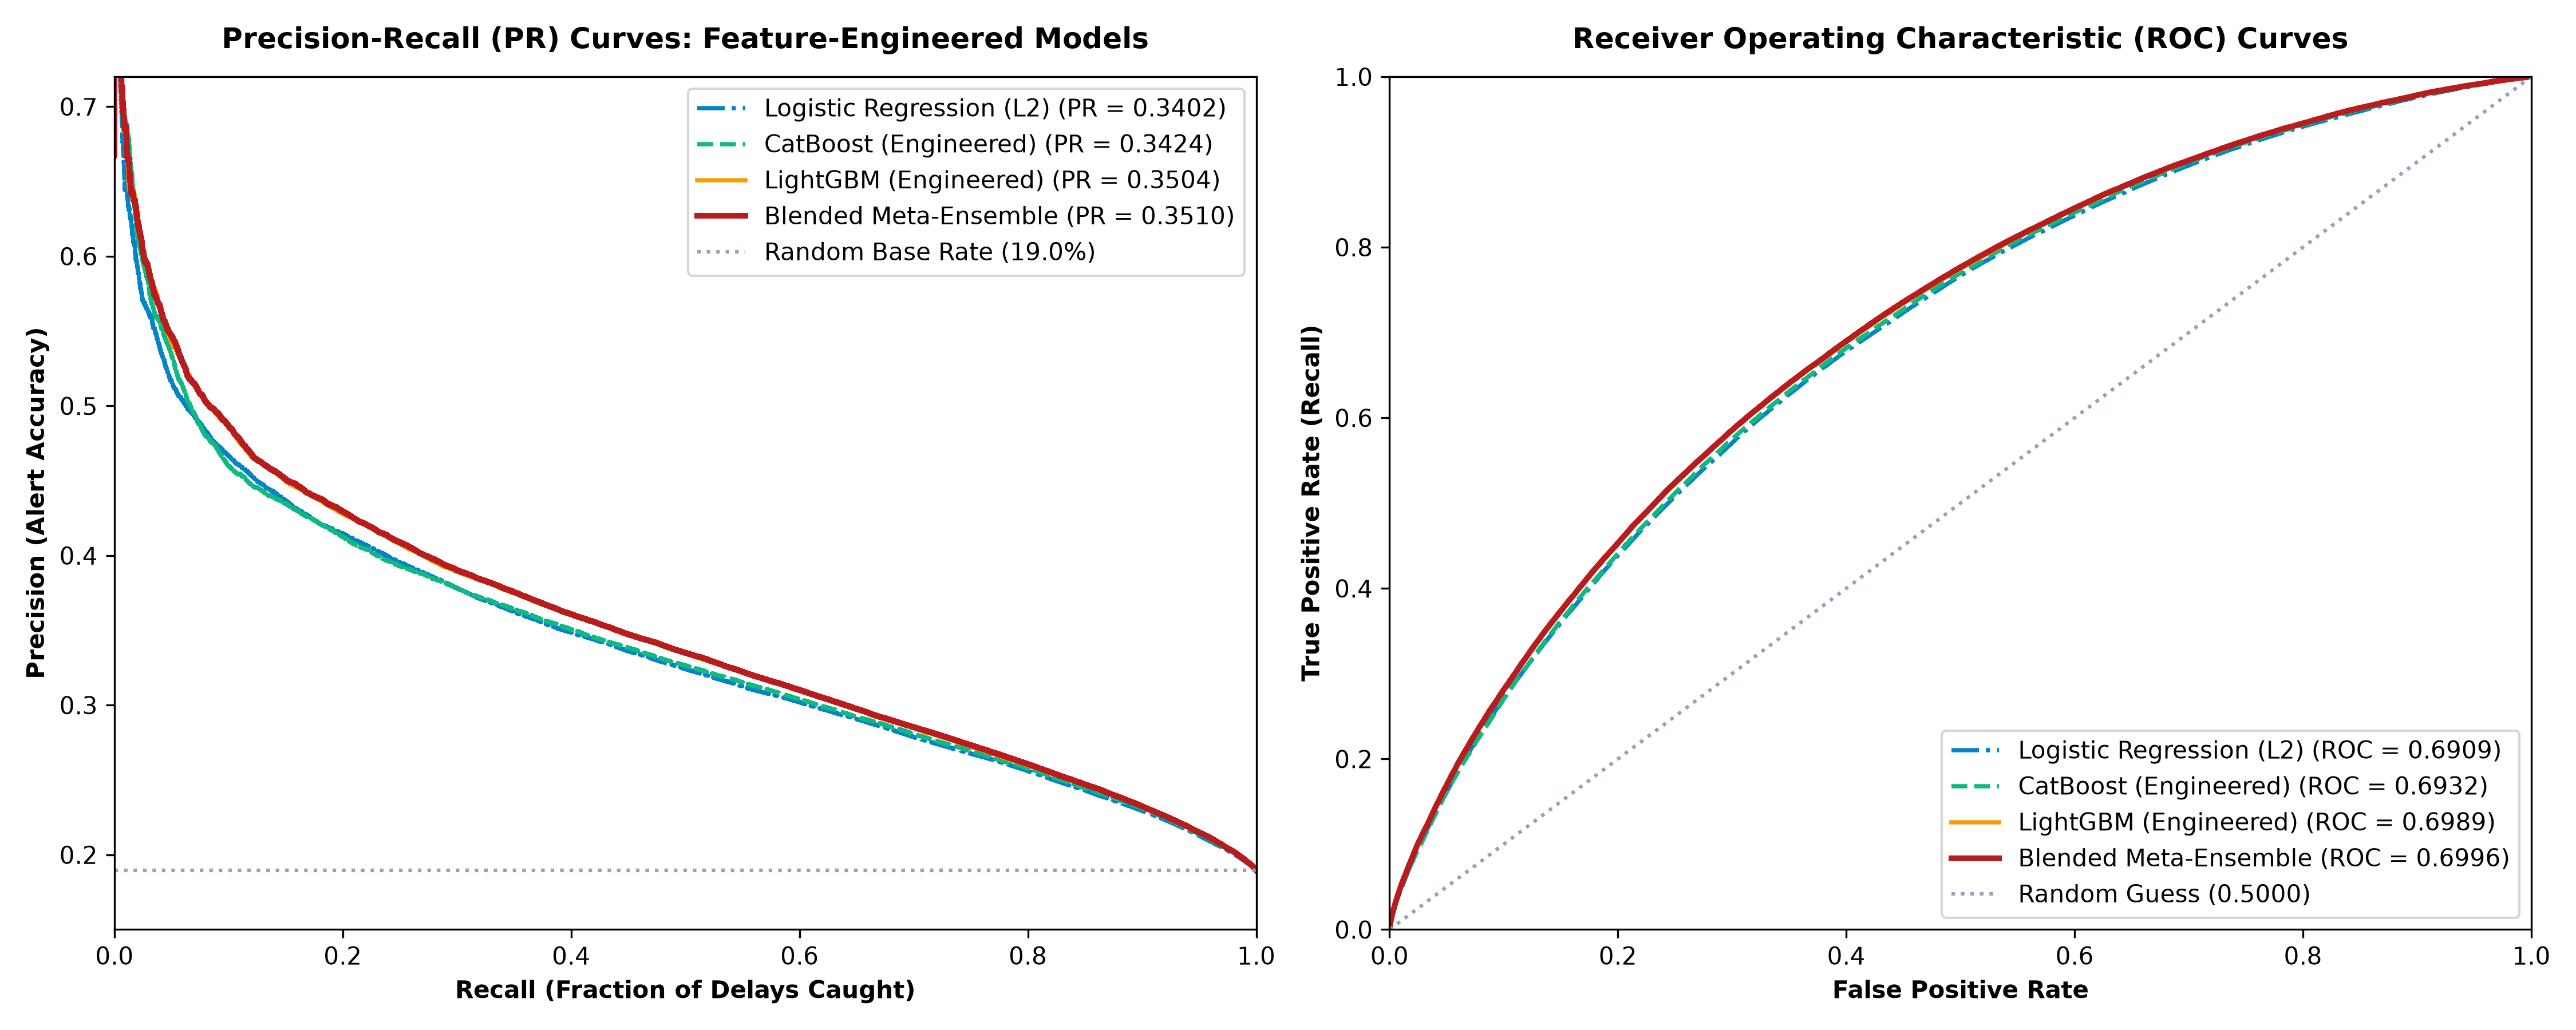

In [ ]:
from IPython.display import Image, display
display(Image(filename="../docs/figures/10_ensemble_pr_roc_comparison.png", width=900))

---
## Chapter 4: What Did the Models Actually Learn?
### Top 16 Predictive Features by Relative Gain

Let's look at which features drove the most information gain:

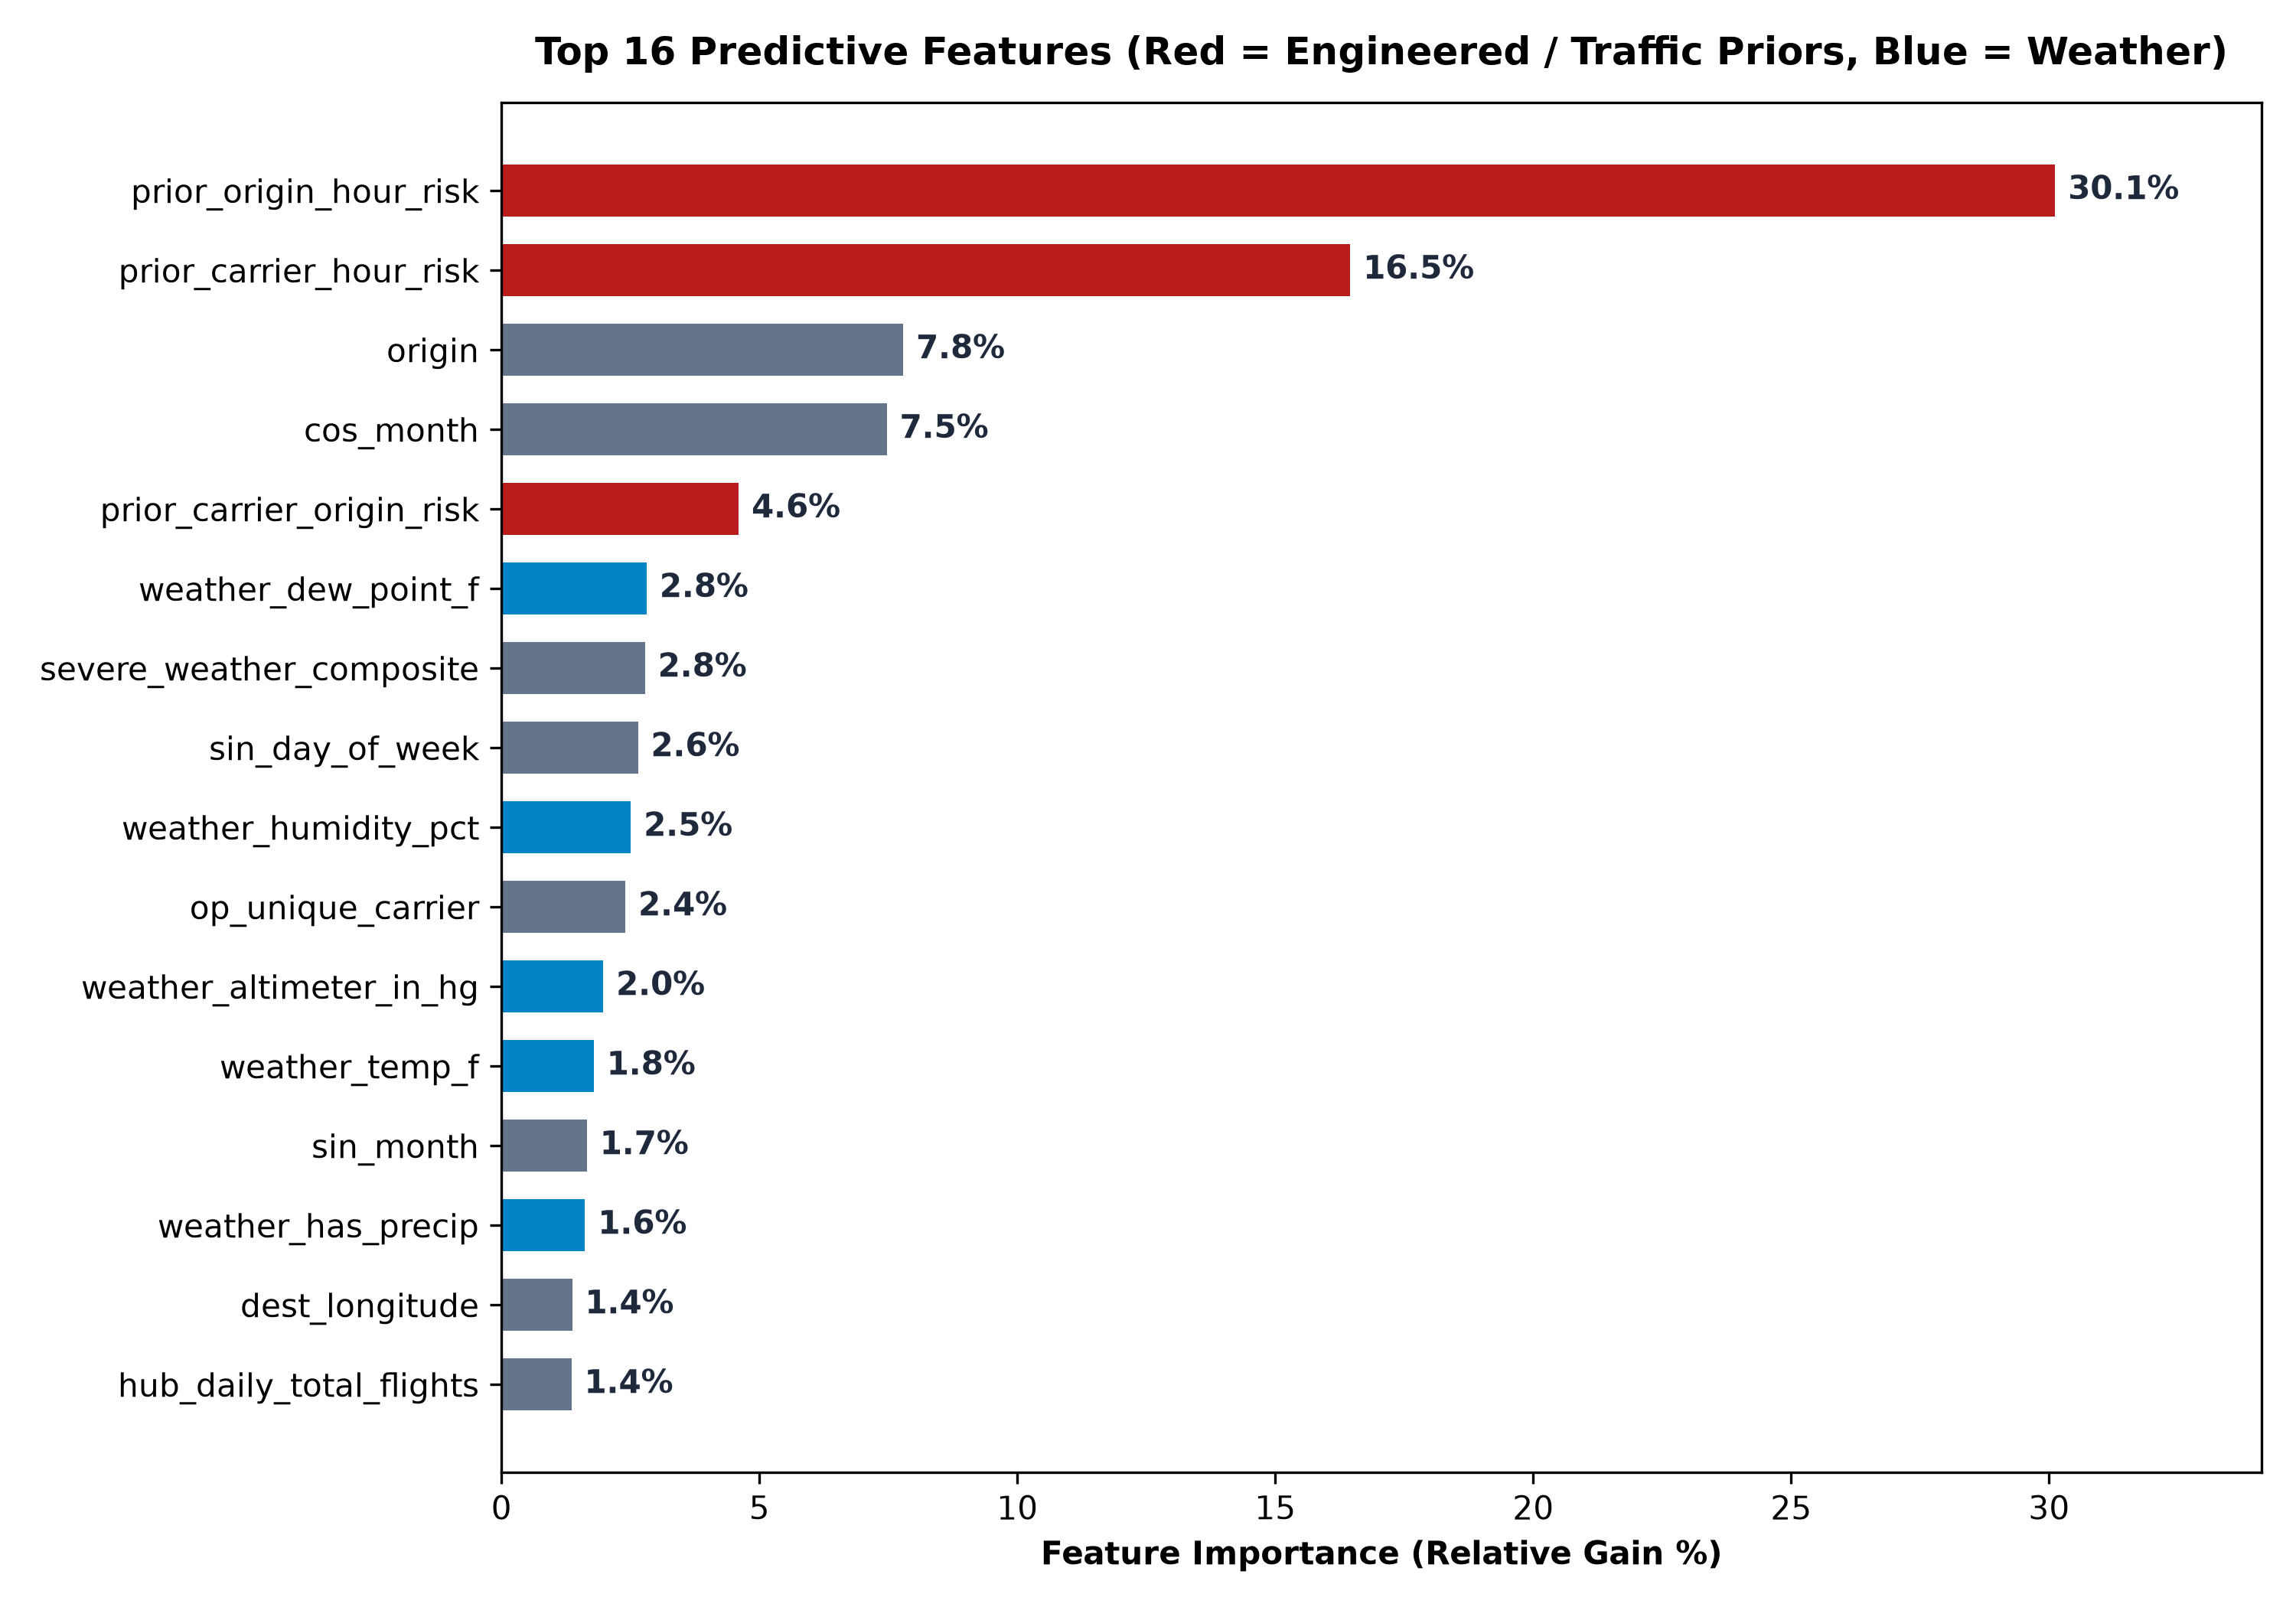

In [ ]:
display(Image(filename="../docs/figures/11_feature_engineered_importance.png", width=800))

---
## Chapter 5: Why Ensembling Works
### The Wisdom of Diverse Crowds in Machine Learning

Why did blending **LightGBM (89.7%)** and **Logistic Regression (10.3%)** beat any individual model on its own?

In data science, every algorithm has an **inductive bias** (a built-in mathematical personality):
- **Decision Trees (LightGBM):** Split feature space with axis-aligned boxes. They excel at finding sharp threshold jumps (e.g., *"If wind gust > 25 knots AND hour == 20: surge delay risk"*). But they can produce step-function cliffs.
- **Logistic Regression:** Fits a smooth linear hyperplane. It never produces sudden jagged cliffs; it provides smooth, gentle gradients.

When you blend them together:
$$\hat{p}_{\text{blend}} = 0.897 \cdot \hat{p}_{\text{LightGBM}} + 0.103 \cdot \hat{p}_{\text{LogisticRegression}}$$
The gentle linear anchor **smooths out the tree model's variance spikes**, creating the lowest Brier calibration error (**0.1415**) and our highest ranking score (**ROC-AUC: 0.6996**).

---
## Chapter 6: The Final Gateway — Test Set Holdout
### Unlocking the Holiday Blizzard Cohort

We have strictly observed the golden rule of machine learning:
**We have never touched, queried, or evaluated on the Test Split (November 1 – December 31, 2025).

Our candidate platform is now fully locked:
- **Champion Model:** Blended Meta-Ensemble (LightGBM + LogReg on 41 Engineered Features).
- **Decision Threshold:** $\tau^* = 0.21$ (optimized for operational F1).
- **Expected Recall:** Catches $\approx 68.7\%$ of all delayed flights.

We are ready to unlock the vault and run the final evaluation on the **885,822 holiday flights**!